# 15. Normalized lexical features and teacher transfer

Owner: rdevasia25. Issue #15. Depends on #7 and #13; reuses #10 feature definitions.

## Goal

Compare three fixed normalized lexical arms, then test transfer from a training-only style teacher. Select the specified six-way blend ablation on internal training rows and confirm the frozen choice separately.

## Setup

Normalization removes some formatting cues. Teacher transfer may recover style signal, but pseudo-label mistakes can copy the teacher shortcut. Keep all controls and losing arms.

In [1]:
import os, re, json, time, unicodedata, warnings, gc
from pathlib import Path
import cloudpickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import vstack
from scipy.special import expit, logit
from IPython import get_ipython
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import FeatureUnion
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score
from threadpoolctl import threadpool_limits
os.environ["EXPANDED_TEXT_HELPERS_ONLY"]="1"
get_ipython().run_line_magic("run", "./10_expanded_text.ipynb")
os.environ["RICH_STYLE_HELPERS_ONLY"]="1"
get_ipython().run_line_magic("run", "./13_rich_style.ipynb")
NAME="15_normalized_transfer"
COMMAND="uv run --locked jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=3600 notebooks/15_normalized_transfer.ipynb"
LEXICAL_GRID=["tfidf", "nb", "two_view"]
BLEND_GRID={"hist":[1.,0.,0.],"hist75_old25":[.75,.25,0.],"hist50_old50":[.5,.5,0.],
            "hist75_nb25":[.75,0.,.25],"hist50_old25_nb25":[.5,.25,.25],"old_soft":[0.,1.,0.]}
STYLE_HIST_SETTINGS={"max_iter":250,"learning_rate":.06,"max_leaf_nodes":15,"min_samples_leaf":30,
                     "l2_regularization":5.,"early_stopping":False,"random_state":42}
CONFIG={"lexical_grid":LEXICAL_GRID,"word":{"ngram_range":[1,3],"min_df":2,"max_features":120000},
    "char":{"analyzer":"char","ngram_range":[3,5],"min_df":2,"max_features":180000},
    "tfidf":{"sublinear_tf":True,"norm":"l2","dtype":"float32"},
    "normalization":"NFKC; canonical quotes/dashes/ellipsis; remove Cf; collapse whitespace; lowercase",
    "classifier":{"tfidf_C":16.,"nb_C":1.,"two_view_C":16.,"solver":"liblinear","max_iter":3000,"seed":42,"tol":1e-4},
    "two_view":"fit original and normalized training copies, each weight .5; average the two inference margins",
    "nb":{"binary":True,"alpha":1.,"ratio":"log normalized class token frequencies; training vocabulary only"},
    "cv":{"n_splits":3,"shuffle":True,"seed":42,"selection":"highest mean fold AUROC; grid order breaks ties"},
    "internal":{"fit_rows":6400,"score_rows":1600,"seed":42,"order":"sorted original manifest indices"},
    "teacher":STYLE_HIST_SETTINGS,"pseudo":{"confidence":.995,"threshold":.5,"classifier_weight":.25,"passes":1,
        "vocabulary":"fit verified internal training only, for both fresh arms",
        "ratio":"treatment also uses assigned pseudo labels, unweighted in NB class frequencies; classifier weights remain .25"},
    "old_soft":{"word":"word13+casechar LR C16 all fit","specialist":"casechar SVM C1 on no-literal-blank fit rows",
        "flag":"literal two consecutive newlines; active only when zero human fit rows have it","offset":2.,
        "score":"mean standardized margins + active flag*2; outer standardization on all eligible unlabeled",
        "specialist_reference":"eligible unlabeled rows without literal blank lines"},
    "blend_grid":BLEND_GRID,"blend_nb_arm":"normalized NB teacher-transfer treatment; supervised control reported separately",
    "blend_selection":"max original internal AUROC with remove-blank and collapse each >= hist-.002; grid order makes exact ties prefer hist",
    "component_scaling":"style clipped logit and NB margin standardized on eligible unlabeled; old arm outer standardized; no test normalization",
    "stress":["original","remove_blank","collapse"],"threads":1,"score_mapping":"sigmoid of weighted standardized scores; not claimed calibrated"}
START=time.perf_counter()


Synthetic feature checks passed. 147 features, schema 3126aec1687a, about 1579 texts/s.


## Checks

Keep the fixed 8,000/2,000 split. The internal 6,400/1,600 split stays inside the original training rows. Notebook 13 supplies the exact rich-style schema; notebook 10 supplies readable NB and original-text definitions in helpers-only mode. No pretrained artifact is required to refit.

In [2]:
parts=load_partitions();train,validation,reference=parts["train"],parts["validation"],parts["unlabeled"]
a,b=train_test_split(np.arange(len(train)),test_size=.2,stratify=train.label,random_state=42)
a,b=np.sort(a),np.sort(b)
internal_train,internal_score=train.iloc[a].reset_index(drop=True),train.iloc[b].reset_index(drop=True)
require(len(internal_train)==6400 and len(internal_score)==1600,"Wrong internal sizes")
require(not set(internal_train.id)&set(internal_score.id),"Internal overlap")
CONFIG["internal_id_sha256"]={"fit":value_hash(internal_train.id.tolist()),"score":value_hash(internal_score.id.tolist())}
CONFIG["fold_id_sha256"]=[]
folds=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=42).split(train.text,train.label))
for fit,score in folds:
    CONFIG["fold_id_sha256"].append({"fit":value_hash(train.id.iloc[fit].tolist()),"score":value_hash(train.id.iloc[score].tolist())})
records=[]
for path in sorted((ROOT/"results/13_rich_style").glob("*.json")):
    record=json.loads(path.read_text())
    if record.get("status")=="completed":records.append((path,record))
require(bool(records),"Completed #13 record is required")
style_record_path,style_record=records[-1]
require(style_record["metrics"]["selected"]=="histgb","Style handoff changed; revise declared hist ablation before running")
require(style_record["config"]["schema_sha256"]==SCHEMA_SHA256,"Rich feature schema changed")
require(style_record["config"]["candidates"]["histgb"]==STYLE_HIST_SETTINGS,"Hist settings differ from #13")
CONFIG["style_dependency"]={"record":str(style_record_path.relative_to(ROOT)),"record_sha256":file_hash(style_record_path),"schema_sha256":SCHEMA_SHA256}
CONFIG["helper_source_sha256"]={name:value_hash(["".join(c["source"]) for c in json.loads((ROOT/"notebooks"/name).read_text())["cells"]]) for name in ["10_expanded_text.ipynb","13_rich_style.ipynb"]}
CONFIG["notebook_source_sha256"]=value_hash(["".join(c["source"]) for c in json.loads((ROOT/"notebooks/15_normalized_transfer.ipynb").read_text())["cells"]])
CONFIG["reference"]={"rows":len(reference),"ordered_id_sha256":value_hash(reference.id.tolist())}
RUN_ID=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
private=ROOT/"artifacts"/NAME/RUN_ID;private.mkdir(parents=True,exist_ok=False)


## Method

Normalize each passage with a fixed function. The two-view arm sees original and normalized copies only from its current fit partition, each at half weight; it averages their inference margins. All lexical vocabulary and NB ratios fit inside each fold.

The transfer control and treatment independently learn the same verified-training vocabulary. The treatment recomputes NB ratios using verified plus assigned pseudo labels, then fits logistic regression with quarter-weight pseudo rows. This differs from #7, which froze vocabulary and IDF and changed only the classifier.

In [3]:
QUOTE_MAP={ord(c):"'" for c in "\u2018\u2019\u201a\u201b"}
QUOTE_MAP.update({ord(c):'"' for c in "\u201c\u201d\u201e\u201f"})
QUOTE_MAP.update({ord(c):"-" for c in "\u2010\u2011\u2012\u2013\u2014\u2015\u2212"})
QUOTE_MAP[ord("\u2026")]="..."
def normalize_text(text):
    text=unicodedata.normalize("NFKC",str(text)).translate(QUOTE_MAP)
    text="".join(c for c in text if unicodedata.category(c)!="Cf")
    return " ".join(text.split()).lower()

def lexical_features(binary=False):
    shared={"min_df":2,"dtype":np.float32,"lowercase":False}
    if binary:
        vector=CountVectorizer;shared.update(binary=True)
    else:
        vector=TfidfVectorizer;shared.update(sublinear_tf=True,norm="l2")
    return FeatureUnion([("word",vector(ngram_range=(1,3),max_features=120000,**shared)),
                         ("char",vector(analyzer="char",ngram_range=(3,5),max_features=180000,**shared))],n_jobs=1)

class NormalizedLexicalModel:
    def __init__(self,kind):self.kind=kind
    def fit(self,texts,labels,pseudo_texts=(),pseudo_labels=()):
        originals=list(texts);normalized=[normalize_text(t) for t in originals];labels=np.asarray(labels)
        self.features_=lexical_features(binary=self.kind=="nb")
        if self.kind=="two_view":
            X=self.features_.fit_transform(originals+normalized)
            y=np.concatenate([labels,labels]);weights=np.full(len(y),.5)
        else:
            X=self.features_.fit_transform(normalized);y=labels;weights=np.ones(len(y))
        self.verified_vocabulary_sha256_=value_hash(self.features_.get_feature_names_out().tolist())
        self.n_features_=int(X.shape[1])
        if len(pseudo_texts):
            require(self.kind=="nb","Pseudo transfer only defined for NB")
            Xp=self.features_.transform([normalize_text(t) for t in pseudo_texts])
            X=vstack([X,Xp],format="csr");y=np.concatenate([y,np.asarray(pseudo_labels)])
            weights=np.concatenate([weights,np.full(len(pseudo_texts),.25)])
        if self.kind=="nb":
            self.ratio_=NBLogRatio(alpha=1.).fit(X,y)
            X=self.ratio_.transform(X)
        self.classifier_=LogisticRegression(C=1. if self.kind=="nb" else 16.,solver="liblinear",max_iter=3000,random_state=42,tol=1e-4)
        self.classifier_.fit(X,y,sample_weight=weights);self.classes_=self.classifier_.classes_
        return self
    def decision_function(self,texts):
        originals=list(texts);normalized=[normalize_text(t) for t in originals]
        X=self.features_.transform(normalized)
        if self.kind=="nb":X=self.ratio_.transform(X)
        margin=self.classifier_.decision_function(X)
        if self.kind=="two_view":margin=.5*(margin+self.classifier_.decision_function(self.features_.transform(originals)))
        return margin
    def predict_proba(self,texts):
        p=expit(self.decision_function(texts));return np.column_stack([1-p,p])

def literal_blank_flags(texts):return np.asarray(["\n\n" in str(t) for t in texts],dtype=bool)
def stress_texts(texts,variant):
    if variant=="original":return list(texts)
    if variant=="remove_blank":return ["\n".join(line for line in str(t).split("\n") if line.strip()) for t in texts]
    if variant=="collapse":return [" ".join(str(t).split()) for t in texts]
    raise ValueError("Unknown stress transform")

class SoftTextArm:
    def fit(self,texts,labels,reference_texts):
        texts=pd.Series(list(texts));labels=np.asarray(labels);keep=~literal_blank_flags(texts)
        self.rule_active_=not bool(literal_blank_flags(texts[labels==0]).any())
        require(set(labels[keep])=={0,1},"No-blank specialist needs both classes")
        self.word_=make_expanded_model({"view":"word_char","learner":"lr","C":16.}).fit(texts,labels)
        self.specialist_=make_expanded_model({"view":"casechar","learner":"svm","C":1.}).fit(texts[keep],labels[keep])
        reference_texts=pd.Series(list(reference_texts))
        self.word_stats_=margin_reference(self.word_,reference_texts)
        self.specialist_stats_=margin_reference(self.specialist_,reference_texts[~literal_blank_flags(reference_texts)])
        raw=self.raw_margin(reference_texts);self.outer_={"mean":float(raw.mean()),"std":float(raw.std())}
        require(self.outer_["std"]>1e-12,"Degenerate old text reference")
        self.fit_rows_=len(texts);self.specialist_rows_=int(keep.sum())
        return self
    def raw_margin(self,texts):
        score=.5*(standardized_margin(self.word_,texts,self.word_stats_)+standardized_margin(self.specialist_,texts,self.specialist_stats_))
        return score+2.*literal_blank_flags(texts)*self.rule_active_
    def decision_function(self,texts):return (self.raw_margin(texts)-self.outer_["mean"])/self.outer_["std"]

class StyleLogitArm:
    def fit(self,texts,labels,reference_texts):
        self.model_=HistGradientBoostingClassifier(**STYLE_HIST_SETTINGS).fit(rich_style_features(texts),labels)
        raw=self.raw_margin(reference_texts);self.statistics_={"mean":float(raw.mean()),"std":float(raw.std())}
        require(self.statistics_["std"]>1e-12,"Degenerate style reference")
        return self
    def probabilities(self,texts):return class1_probabilities(self.model_,rich_style_features(texts))
    def raw_margin(self,texts):return logit(np.clip(self.probabilities(texts),1e-7,1-1e-7))
    def decision_function(self,texts):return (self.raw_margin(texts)-self.statistics_["mean"])/self.statistics_["std"]

class TransferBlend:
    classes_=np.array([0,1])
    def __init__(self,style,old,nb,nb_stats,weights):
        self.style,self.old,self.nb,self.nb_stats,self.weights=style,old,nb,nb_stats,np.asarray(weights)
    def components(self,texts):
        return np.column_stack([self.style.decision_function(texts),self.old.decision_function(texts),standardized_margin(self.nb,texts,self.nb_stats)])
    def decision_function(self,texts):return self.components(texts)@self.weights
    def predict_proba(self,texts):
        p=expit(self.decision_function(texts));return np.column_stack([1-p,p])

def fit_teacher_transfer(fit_frame,reference_frame):
    start=time.perf_counter();style=StyleLogitArm().fit(fit_frame.text,fit_frame.label,reference_frame.text)
    teacher_seconds=time.perf_counter()-start
    probabilities=style.probabilities(reference_frame.text)
    keep=np.maximum(probabilities,1-probabilities)>=.995;assigned=(probabilities[keep]>=.5).astype(int)
    start=time.perf_counter();control=NormalizedLexicalModel("nb").fit(fit_frame.text,fit_frame.label)
    control_seconds=time.perf_counter()-start
    start=time.perf_counter();treatment=NormalizedLexicalModel("nb").fit(fit_frame.text,fit_frame.label,reference_frame.text.iloc[np.flatnonzero(keep)],assigned)
    treatment_seconds=time.perf_counter()-start
    require(control.verified_vocabulary_sha256_==treatment.verified_vocabulary_sha256_,"Transfer changed vocabulary")
    counts={"verified_rows":len(fit_frame),"eligible_rows":len(reference_frame),"accepted":int(keep.sum()),
        "accepted_human":int((assigned==0).sum()),"accepted_AI":int((assigned==1).sum()),"pseudo_weighted_mass":float(.25*keep.sum()),
        "teacher_seconds":teacher_seconds,"control_seconds":control_seconds,"treatment_seconds":treatment_seconds,
        "vocabulary_sha256":control.verified_vocabulary_sha256_}
    return style,control,treatment,counts,keep,assigned,probabilities


## Run

Save the full plan before fitting. First choose lexical settings by training CV and choose blend weights on internal 1,600 rows. Only after both selections are saved do full 8,000-row fits and frozen validation confirmation. Stress tests transform evaluation text only, with frozen models and reference statistics.

In [4]:
fixture=normalize_text("\uff21\u201cHi\u201d\u2014x\u200b\n y\u2026")
require(fixture=='a"hi"-x y...',"Unicode normalization fixture failed")
require(normalize_text(fixture)==fixture,"Normalization must be idempotent")
require(stress_texts(["a\n \nb"],"remove_blank")==["a\nb"],"Remove-blank fixture failed")
plan_path=ROOT/"results"/NAME/f"{RUN_ID}-plan.json"
save_new_json(plan_path,{"config":CONFIG,"config_sha256":value_hash(CONFIG),"saved_before_fit":True,"split_sha256":parts["split"]["split_sha256"]})
artifacts=[plan_path];cv_rows=[]
try:
    oof={};candidate_rows=[]
    with threadpool_limits(limits=1),warnings.catch_warnings():
        warnings.simplefilter("error",ConvergenceWarning)
        for kind in LEXICAL_GRID:
            oof[kind]=np.full(len(train),np.nan);start=time.perf_counter()
            for fold,(fit,score) in enumerate(folds):
                fold_start=time.perf_counter()
                model=NormalizedLexicalModel(kind).fit(train.text.iloc[fit],train.label.iloc[fit])
                values=model.decision_function(train.text.iloc[score]);oof[kind][score]=values
                cv_rows.append({"candidate":kind,"fold":fold,"auroc":float(roc_auc_score(train.label.iloc[score],values)),"seconds":time.perf_counter()-fold_start})
                del model;gc.collect()
            scores=[r["auroc"] for r in cv_rows if r["candidate"]==kind]
            candidate_rows.append({"candidate":kind,"cv_mean":float(np.mean(scores)),"cv_std":float(np.std(scores)),
                "pooled_oof_auroc":float(roc_auc_score(train.label,oof[kind])),"cv_seconds":time.perf_counter()-start})
        selected_lexical=max(candidate_rows,key=lambda r:r["cv_mean"])["candidate"]
        lexical_selection_path=ROOT/"results"/NAME/f"{RUN_ID}-lexical-selection.json"
        save_new_json(lexical_selection_path,{"selected":selected_lexical,"candidate_results":candidate_rows,"validation_inspected":False});artifacts.append(lexical_selection_path)
        path=private/"lexical_oof.csv";pd.DataFrame({"id":train.id,**oof}).to_csv(path,index=False);artifacts.append(path)
        internal_start=time.perf_counter()
        style,control,treatment,acceptance,keep,assigned,teacher_probability=fit_teacher_transfer(internal_train,reference)
        path=private/"accepted_internal_pseudo.csv"
        pd.DataFrame({"id":reference.id.to_numpy()[keep],"pseudo_label":assigned,"teacher_p_ai":teacher_probability[keep]}).to_csv(path,index=False);artifacts.append(path)
        acceptance_path=ROOT/"results"/NAME/f"{RUN_ID}-acceptance.json"
        save_new_json(acceptance_path,{"acceptance":acceptance,"internal_score_inspected":False});artifacts.append(acceptance_path)
        internal_transfer=[]
        for name,model in [("control",control),("treatment",treatment)]:
            internal_transfer.append({"arm":name,"train_auroc":float(roc_auc_score(internal_train.label,model.decision_function(internal_train.text))),
                "internal_auroc":float(roc_auc_score(internal_score.label,model.decision_function(internal_score.text)))})
        old=SoftTextArm().fit(internal_train.text,internal_train.label,reference.text)
        nb_stats=margin_reference(treatment,reference.text)
        internal_base=TransferBlend(style,old,treatment,nb_stats,[1,0,0])
        internal_matrices={variant:internal_base.components(stress_texts(internal_score.text,variant)) for variant in CONFIG["stress"]}
        grid_results=[]
        for name,weights in BLEND_GRID.items():
            row={"candidate":name,"weights":weights}
            row.update({variant:float(roc_auc_score(internal_score.label,matrix@weights)) for variant,matrix in internal_matrices.items()})
            grid_results.append(row)
        hist=grid_results[0]
        for row in grid_results:
            row["remove_blank_pass"]=row["remove_blank"]>=hist["remove_blank"]-.002
            row["collapse_pass"]=row["collapse"]>=hist["collapse"]-.002
            row["eligible"]=row["remove_blank_pass"] and row["collapse_pass"]
        selected_blend=max([r for r in grid_results if r["eligible"]],key=lambda r:r["original"])
        blend_selection_path=ROOT/"results"/NAME/f"{RUN_ID}-blend-selection.json"
        save_new_json(blend_selection_path,{"selected":selected_blend,"grid":grid_results,"validation_inspected":False,
            "old_rule_active":old.rule_active_,"old_specialist_rows":old.specialist_rows_,"reference_stats":{"style":style.statistics_,"old_outer":old.outer_,"nb":nb_stats}})
        artifacts.append(blend_selection_path)
        internal_seconds=time.perf_counter()-internal_start
        # Save internal arms for repeatability; no validation rows have been scored yet.
        for name,model in [("internal_style",style),("internal_nb_control",control),("internal_nb_treatment",treatment),("internal_old_soft",old)]:
            path=private/f"{name}.pkl"
            with path.open("wb") as handle:cloudpickle.dump(model,handle)
            artifacts.append(path)
        final_lexical_rows=[];saved_lexical={}
        for kind in LEXICAL_GRID:
            start=time.perf_counter();model=NormalizedLexicalModel(kind).fit(train.text,train.label);fit_seconds=time.perf_counter()-start
            train_margin=model.decision_function(train.text);valid_margin=model.decision_function(validation.text)
            final_lexical_rows.append({"candidate":kind,"train_auroc":float(roc_auc_score(train.label,train_margin)),
                "validation_auroc":float(roc_auc_score(validation.label,valid_margin)),"fit_seconds":fit_seconds,"features":model.n_features_})
            path=private/f"lexical_{kind}.pkl"
            with path.open("wb") as handle:cloudpickle.dump(model,handle)
            artifacts.append(path);saved_lexical[kind]=str(path.relative_to(ROOT))
            with path.open("rb") as handle:restored=cloudpickle.load(handle)
            difference=float(np.max(np.abs(restored.decision_function(validation.text)-valid_margin)))
            require(difference<=1e-12,"Lexical reload changed margins")
            final_lexical_rows[-1]["max_reload_margin_difference"]=difference
            for name,frame,score in [("train",train,train_margin),("validation",validation,valid_margin)]:
                path=private/f"lexical_{kind}_{name}.csv";pd.DataFrame({"id":frame.id,"margin":score,"p_ai":expit(score)}).to_csv(path,index=False);artifacts.append(path)
            del model,restored;gc.collect()
        full_start=time.perf_counter()
        full_style,full_control,full_nb,full_acceptance,full_keep,full_assigned,full_teacher_probability=fit_teacher_transfer(train,reference)
        full_old=SoftTextArm().fit(train.text,train.label,reference.text)
        full_nb_stats=margin_reference(full_nb,reference.text)
        final_blend=TransferBlend(full_style,full_old,full_nb,full_nb_stats,selected_blend["weights"])
        full_refit_seconds=time.perf_counter()-full_start
        confirmation_rows=[]
        for variant in CONFIG["stress"]:
            text=stress_texts(validation.text,variant)
            probabilities=class1_probabilities(final_blend,text)
            metrics=evaluate_predictions(validation,pd.DataFrame({"id":validation.id,"p_ai":probabilities}))
            confirmation_rows.append({"variant":variant,**metrics})
            path=private/f"blend_validation_{variant}.csv";pd.DataFrame({"id":validation.id,"p_ai":probabilities}).to_csv(path,index=False);artifacts.append(path)
        train_pred=pd.DataFrame({"id":train.id,"p_ai":class1_probabilities(final_blend,train.text)})
        train_metrics=evaluate_predictions(train,train_pred)
        path=private/"blend_train.csv";train_pred.to_csv(path,index=False);artifacts.append(path)
        model_path=private/"selected_blend.pkl"
        with model_path.open("wb") as handle:cloudpickle.dump(final_blend,handle)
        artifacts.append(model_path)
        with model_path.open("rb") as handle:restored=cloudpickle.load(handle)
        expected=pd.read_csv(private/"blend_validation_original.csv",dtype={"id":"string"},float_precision="round_trip")
        require(expected.id.tolist()==validation.id.tolist(),"Reload reference IDs changed")
        reload_difference=float(np.max(np.abs(class1_probabilities(restored,validation.text)-expected.p_ai.to_numpy())))
        require(reload_difference<=1e-12,"Blend reload changed probabilities")
        standalone_spec={"selected_weights":selected_blend["weights"],"selected_lexical":selected_lexical,
            "old_rule_active":full_old.rule_active_,"old_specialist_fit_rows":full_old.specialist_rows_,
            "full_transfer_acceptance":full_acceptance,"style_schema":SCHEMA,"style_schema_sha256":SCHEMA_SHA256,
            "reference_stats":{"style":full_style.statistics_,"word":full_old.word_stats_,"specialist":full_old.specialist_stats_,
                               "old_outer":full_old.outer_,"nb":full_nb_stats},"config":CONFIG}
        spec_path=private/"refit_spec.json";save_new_json(spec_path,standalone_spec);artifacts.append(spec_path)
except Exception as exc:
    record_run(NAME,COMMAND,CONFIG,SEED,len(train),len(validation),{"validation_auroc":None,"completed_cv":cv_rows},
        time.perf_counter()-START,status="failed",error_type=type(exc).__name__)
    raise RuntimeError("Normalized transfer failed; see safe run record and private execution log.") from None


## Results

Internal transfer and blend comparisons use only the original training partition. The separate frozen validation confirmation follows saved selections and does not choose new settings. Validation was reused earlier in the project, so these are conditional comparisons, not an untouched test. Formatting stress is an ablation, not evidence about hidden Kaggle sources. Probabilities are bounded scores without a calibration claim.

,candidate,cv_mean,cv_std,pooled_oof_auroc,cv_seconds
0,tfidf,0.952118,0.004587,0.952100,70.154866
1,nb,0.961977,0.005295,0.961865,63.387716
2,two_view,0.958631,0.004107,0.958667,114.659344


,candidate,train_auroc,validation_auroc,fit_seconds,features,max_reload_margin_difference
0,tfidf,1.0,0.956511,27.045745,300000,0.0
1,nb,1.0,0.966657,29.103715,300000,0.0
2,two_view,1.0,0.963252,48.949948,300000,0.0


,verified_rows,eligible_rows,accepted,accepted_human,accepted_AI,pseudo_weighted_mass,teacher_seconds,control_seconds,treatment_seconds,vocabulary_sha256
0,6400,3000,2205,1012,1193,551.25,8.212502,21.90935,28.960762,5068e9bec638a33dcc42a3146f8fba184b939d9a4ee1cb...


,arm,train_auroc,internal_auroc
0,control,1.0,0.959956
1,treatment,1.0,0.964239


,candidate,weights,original,remove_blank,collapse,remove_blank_pass,collapse_pass,eligible
0,hist,"[1.0, 0.0, 0.0]",0.997975,0.982770,0.809845,True,True,True
1,hist75_old25,"[0.75, 0.25, 0.0]",0.998808,0.987973,0.852427,True,True,True
2,hist50_old50,"[0.5, 0.5, 0.0]",0.998969,0.988691,0.880247,True,True,True
3,hist75_nb25,"[0.75, 0.0, 0.25]",0.998900,0.992081,0.906537,True,True,True
4,hist50_old25_nb25,"[0.5, 0.25, 0.25]",0.999022,0.992444,0.931547,True,True,True
5,old_soft,"[0.0, 1.0, 0.0]",0.994148,0.957148,0.908414,False,True,False


,variant,auroc,accuracy_at_0_5,rows
0,original,0.998492,0.9845,2000
1,remove_blank,0.992831,0.8720,2000
2,collapse,0.931158,0.8075,2000


Lexical CV choice: nb; internal blend choice: hist50_old25_nb25
Internal old-rule active: True; full-fit old-rule active: True
Internal section 171.08s; full blend refit 135.94s; reload difference 0


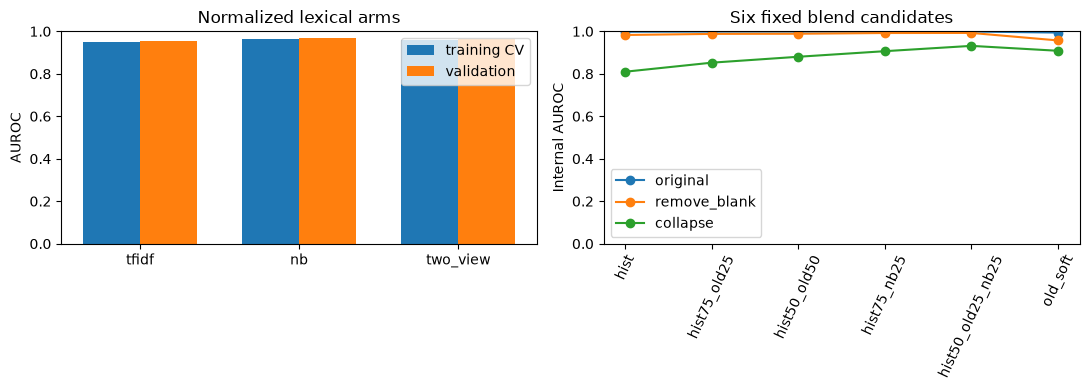

In [5]:
display(pd.DataFrame(candidate_rows));display(pd.DataFrame(final_lexical_rows))
display(pd.DataFrame([acceptance]));display(pd.DataFrame(internal_transfer));display(pd.DataFrame(grid_results))
display(pd.DataFrame(confirmation_rows))
print(f"Lexical CV choice: {selected_lexical}; internal blend choice: {selected_blend['candidate']}")
print(f"Internal old-rule active: {old.rule_active_}; full-fit old-rule active: {full_old.rule_active_}")
print(f"Internal section {internal_seconds:.2f}s; full blend refit {full_refit_seconds:.2f}s; reload difference {reload_difference:.3g}")
fig,axes=plt.subplots(1,2,figsize=(11,4))
x=np.arange(len(candidate_rows))
axes[0].bar(x-.18,[r["cv_mean"] for r in candidate_rows],width=.36,label="training CV")
axes[0].bar(x+.18,[r["validation_auroc"] for r in final_lexical_rows],width=.36,label="validation")
axes[0].set(xticks=x,xticklabels=LEXICAL_GRID,ylim=(0,1),ylabel="AUROC",title="Normalized lexical arms");axes[0].legend()
for variant in CONFIG["stress"]:
    axes[1].plot([r["candidate"] for r in grid_results],[r[variant] for r in grid_results],marker="o",label=variant)
axes[1].set(ylim=(0,1),ylabel="Internal AUROC",title="Six fixed blend candidates");axes[1].tick_params(axis="x",rotation=65);axes[1].legend()
fig.tight_layout();plot_path=private/"comparison.png";fig.savefig(plot_path,dpi=140);artifacts.append(plot_path);plt.show()


## Takeaway

- Tried normalized TF-IDF, binary NB weighting, two-view training, and one fixed style-teacher transfer pass.
- Tables retain controls, weaker arms, the six-way stress guardrails, and separate confirmation. Small point gains alone do not establish generalization.
- Next: #17 repeats the blend grid with augmented style; #18 handles final refits and course handoff. No automatic Kaggle upload.

## Save

Keep models, pseudo-label rows, feature schema, reference statistics, and row predictions ignored. Save safe aggregates with every measured arm. The private pointer provides lexical models, the confirmed ablation blend, and a standalone refit specification. This does not select the final competition model.

In [6]:
CONFIG["extra_versions"]={k:importlib.metadata.version(k) for k in ["cloudpickle","matplotlib","threadpoolctl"]}
metrics={"validation_auroc":confirmation_rows[0]["auroc"],"train_auroc":train_metrics["auroc"],
    "selected_lexical":selected_lexical,"lexical_candidate_results":candidate_rows,"lexical_fold_results":cv_rows,
    "lexical_confirmation":final_lexical_rows,"internal_transfer_acceptance":acceptance,"internal_transfer_results":internal_transfer,
    "internal_blend_grid":grid_results,"selected_internal_blend":selected_blend,"frozen_confirmation":confirmation_rows,
    "full_transfer_acceptance":full_acceptance,"internal_seconds":internal_seconds,"full_blend_refit_seconds":full_refit_seconds,
    "internal_old_rule_active":old.rule_active_,"full_old_rule_active":full_old.rule_active_,"max_reload_difference":reload_difference}
record_path=record_run(NAME,COMMAND,CONFIG,SEED,len(train),len(validation),metrics,time.perf_counter()-START,artifacts=artifacts)
pointer={"result":str(record_path.relative_to(ROOT)),"result_sha256":file_hash(record_path),
    "split_sha256":parts["split"]["split_sha256"],"selected_lexical":selected_lexical,"lexical_models":saved_lexical,
    "model":str(model_path.relative_to(ROOT)),"refit_spec":str(spec_path.relative_to(ROOT)),
    "selected_internal_blend":selected_blend["candidate"],"train_predictions":str((private/"blend_train.csv").relative_to(ROOT)),
    "validation_predictions":str((private/"blend_validation_original.csv").relative_to(ROOT)),
    "artifacts":{str(p.relative_to(ROOT)):file_hash(p) for p in artifacts}}
target=ROOT/"artifacts"/NAME/"latest.json";temporary=target.with_suffix(".tmp")
temporary.write_text(json.dumps(pointer,sort_keys=True,indent=2)+"\n");temporary.replace(target)
print("Saved normalized lexical, transfer, and blend ablation results.")


Saved normalized lexical, transfer, and blend ablation results.
